# LSTM on returns, and a direct mean-reversion check

**Goal.** Test an LSTM on daily returns, then test mean reversion directly instead of treating the network's errors as a signal.

**Method.** A smaller LSTM on 30 days of NVDA returns, early stopping, scaler fit on training returns only. The same model is rerun on NVDA, AAPL, MSFT, SPY, and QQQ across five seeds, charging 0.1% when the position changes. Separately, the price LSTM is checked for directional calls. Then next-day returns are measured after a fixed gain (2% to 5%, and a 3% screen across tickers) and after a gain larger than 2 trailing 20-day standard deviations.

**Result.** The single NVDA returns run printed 51.8% directional accuracy versus 50.9% for always guessing up. After fees, all five NVDA seeds beat buy and hold. AAPL, MSFT, SPY, and QQQ did not. After a daily gain above 3%, QQQ's next day was down 62.7% of the time (51 days). The volatility-adjusted version of that screen, split by year, is not a stable daily edge. The price-error chart later in this notebook is a separate fit: its title is the last-250-day average, not the $8.18 full-test error from notebook 04. The intraday follow-up is notebook 05b.


In [ ]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


[*********************100%***********************]  1 of 1 completed

Epoch 1/50


50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.9850 - val_loss: 1.1736
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9825 - val_loss: 1.1750
Epoch 3/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9844 - val_loss: 1.1694
Epoch 4/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9805 - val_loss: 1.1658
Epoch 5/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9830 - val_loss: 1.1656
Epoch 6/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9745 - val_loss: 1.1646
Epoch 7/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9779 - val_loss: 1.1644
Epoch 8/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9789 - val_loss: 1.1611
Epoch 9/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9786 - val_loss: 1.1584
Epoch 10/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9748 - val_loss: 1.1575
Epoch 11/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9708 - val_loss: 1.1583
Epoch 12/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9756 - val_loss: 1.1530


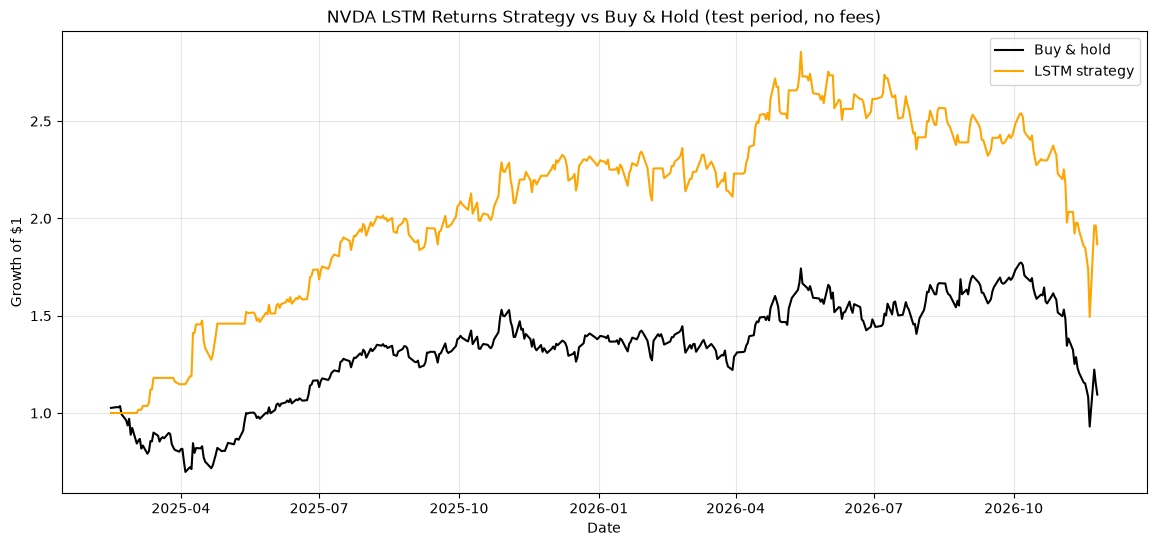

In [2]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

ticker = "NVDA"
window = 30   # last 30 days of returns -> predict tomorrow's return

# Download data and convert prices to daily % returns
df = yf.download(ticker, start="2018-01-01", multi_level_index=False)[["Close"]].dropna()
df["Return"] = df["Close"].pct_change()
df = df.dropna()
rets = df["Return"].values.reshape(-1, 1)

# Time-based split
split = int(len(rets) * 0.8)

# Scale returns (fit on training only)
scaler = StandardScaler().fit(rets[:split])
scaled = scaler.transform(rets)

def make_windows(data, start, end):
    X, y = [], []
    for i in range(start, end):
        X.append(data[i - window:i, 0])
        y.append(data[i, 0])
    return np.array(X).reshape(-1, window, 1), np.array(y)

X_train, y_train = make_windows(scaled, window, split)
X_test, y_test = make_windows(scaled, split, len(scaled))

# Smaller model + early stopping to fight overfitting
model = Sequential([
    Input(shape=(window, 1)),
    LSTM(32),
    Dropout(0.2),
    Dense(1),
])
model.compile(optimizer="adam", loss="mse")
model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.1,
          callbacks=[EarlyStopping(patience=5, restore_best_weights=True)], verbose=1)

# Predict returns on the test period
pred = scaler.inverse_transform(model.predict(X_test)).flatten()
actual = rets[split:].flatten()

# 1) Direction accuracy vs. "always guess up"
model_acc = np.mean(np.sign(pred) == np.sign(actual))
always_up = np.mean(actual > 0)
print(f"\nModel direction accuracy: {model_acc:.1%}")
print(f"'Always up' baseline:     {always_up:.1%}")
print(f"Days model said 'up':     {np.mean(pred > 0):.1%}")

# 2) Simple strategy: hold when model predicts up, cash otherwise (no fees)
strat = np.where(pred > 0, actual, 0)
equity_strat = np.cumprod(1 + strat)
equity_bh = np.cumprod(1 + actual)
print(f"\nStrategy return:   {equity_strat[-1] - 1:+.1%}")
print(f"Buy & hold return: {equity_bh[-1] - 1:+.1%}")

test_dates = df.index[split:]
plt.figure(figsize=(14, 6))
plt.plot(test_dates, equity_bh, label="Buy & hold", color="black")
plt.plot(test_dates, equity_strat, label="LSTM strategy", color="orange")
plt.title(f"{ticker} LSTM Returns Strategy vs Buy & Hold (test period, no fees)")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [3]:
import yfinance as yf
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

window = 30
fee = 0.001   # 0.1% cost every time the position changes

def run(r, seed):
    tf.keras.utils.set_random_seed(seed)
    split = int(len(r) * 0.8)
    sc = StandardScaler().fit(r[:split])
    s = sc.transform(r)
    X = np.array([s[i - window:i, 0] for i in range(window, len(s))]).reshape(-1, window, 1)
    y = s[window:, 0]
    cut = split - window
    model = Sequential([Input(shape=(window, 1)), LSTM(32), Dropout(0.2), Dense(1)])
    model.compile(optimizer="adam", loss="mse")
    model.fit(X[:cut], y[:cut], epochs=50, batch_size=32, validation_split=0.1,
              callbacks=[EarlyStopping(patience=5, restore_best_weights=True)], verbose=0)
    pred = sc.inverse_transform(model.predict(X[cut:], verbose=0)).flatten()
    actual = r[split:].flatten()
    pos = (pred > 0).astype(float)
    trades = np.abs(np.diff(np.concatenate([[0], pos])))
    strat = pos * actual - trades * fee
    return np.prod(1 + strat) - 1, pos.mean()

for t in ["NVDA", "AAPL", "MSFT", "SPY", "QQQ"]:
    df = yf.download(t, start="2018-01-01", multi_level_index=False, progress=False)[["Close"]].dropna()
    r = df["Close"].pct_change().dropna().values.reshape(-1, 1)
    bh = np.prod(1 + r[int(len(r) * 0.8):].flatten()) - 1
    res = [run(r, seed) for seed in range(5)]
    runs = ", ".join(f"{x[0]:+.0%}" for x in res)
    print(f"{t:5} buy&hold {bh:+.0%} | strategy (5 seeds): {runs} | avg days long {np.mean([x[1] for x in res]):.0%}")


NVDA  buy&hold +10% | strategy (5 seeds): +51%, +62%, +36%, +55%, +76% | avg days long 85%
AAPL  buy&hold +48% | strategy (5 seeds): +23%, +48%, +54%, +3%, +42% | avg days long 95%
MSFT  buy&hold +21% | strategy (5 seeds): +11%, +17%, +12%, +6%, +24% | avg days long 91%
SPY   buy&hold +20% | strategy (5 seeds): +8%, +20%, +18%, +0%, +22% | avg days long 95%
QQQ   buy&hold +19% | strategy (5 seeds): +12%, +19%, +7%, -9%, +14% | avg days long 91%


In [2]:
import yfinance as yf
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

ticker = "NVDA"
window = 60

# Download data
df = yf.download(ticker, start="2018-01-01", multi_level_index=False, progress=False)[["Close"]].dropna()
prices = df["Close"].values.reshape(-1, 1)
split = int(len(prices) * 0.8)

# Scale (fit on training only)
scaler = MinMaxScaler().fit(prices[:split])
scaled = scaler.transform(prices)

# 60-day windows
X = np.array([scaled[i - window:i, 0] for i in range(window, len(scaled))]).reshape(-1, window, 1)
y = scaled[window:, 0]
cut = split - window

# Train LSTM
model = Sequential([Input(shape=(window, 1)), LSTM(50, return_sequences=True), Dropout(0.2),
                    LSTM(50), Dropout(0.2), Dense(1)])
model.compile(optimizer="adam", loss="mse")
model.fit(X[:cut], y[:cut], epochs=20, batch_size=32, verbose=0)

# Predictions in dollars
pred = scaler.inverse_transform(model.predict(X[cut:], verbose=0)).flatten()
actual = prices[split:].flatten()
today_close = prices[split - 1:-1].flatten()

# His version (error) vs correct version (forecast)
his_move = pred - actual
predicted_move = pred - today_close
actual_move = actual - today_close

print(f"His 'movement' days negative:     {np.mean(his_move < 0):.0%}")
print(f"Correct predicted move negative:  {np.mean(predicted_move < 0):.0%}")
print(f"Actual down days in test period:  {np.mean(actual_move < 0):.0%}\n")

# Test multiple thresholds
for threshold in [2, 4, 6, 8, 10]:
    signals = np.abs(predicted_move) > threshold
    if signals.sum() == 0:
        print(f"Threshold ${threshold:>2}: no signal days")
        continue
    correct = np.sign(predicted_move[signals]) == np.sign(actual_move[signals])
    print(f"Threshold ${threshold:>2}: {signals.sum():3} signal days | direction correct {correct.mean():.1%}")


His 'movement' days negative:     91%
Correct predicted move negative:  92%
Actual down days in test period:  49%

Threshold $ 2: 437 signal days | direction correct 48.7%
Threshold $ 4: 408 signal days | direction correct 50.2%
Threshold $ 6: 366 signal days | direction correct 51.6%
Threshold $ 8: 326 signal days | direction correct 52.1%
Threshold $10: 283 signal days | direction correct 53.4%


In [3]:
r = df["Close"].pct_change()
next_r = r.shift(-1)
test = df.index >= df.index[split]

for cutoff in [0.02, 0.03, 0.04, 0.05]:
    days = test & (r > cutoff)
    down_next = (next_r[days] < 0).mean()
    print(f"After NVDA up >{cutoff:.0%}: {days.sum():3} days | next day down {down_next:.1%}")


After NVDA up >2%:  90 days | next day down 51.1%
After NVDA up >3%:  44 days | next day down 59.1%
After NVDA up >4%:  22 days | next day down 54.5%
After NVDA up >5%:  12 days | next day down 58.3%


In [4]:
for t in ["NVDA", "AMD", "TSLA", "AAPL", "QQQ"]:
    d = yf.download(t, start="2018-01-01", multi_level_index=False, progress=False)["Close"]
    r = d.pct_change()
    nr = r.shift(-1)
    days = r > 0.03
    print(f"{t:5} up>3%: {days.sum():4} days | next day down {(nr[days] < 0).mean():.1%} "
          f"| avg next-day return {nr[days].mean():+.2%} | normal down rate {(nr < 0).mean():.1%}")


NVDA  up>3%:  334 days | next day down 50.0% | avg next-day return -0.14% | normal down rate 46.4%
AMD   up>3%:  372 days | next day down 49.5% | avg next-day return +0.13% | normal down rate 48.3%
TSLA  up>3%:  416 days | next day down 47.1% | avg next-day return +0.46% | normal down rate 48.3%
AAPL  up>3%:  109 days | next day down 55.0% | avg next-day return -0.27% | normal down rate 46.3%
QQQ   up>3%:   51 days | next day down 62.7% | avg next-day return -0.81% | normal down rate 44.1%


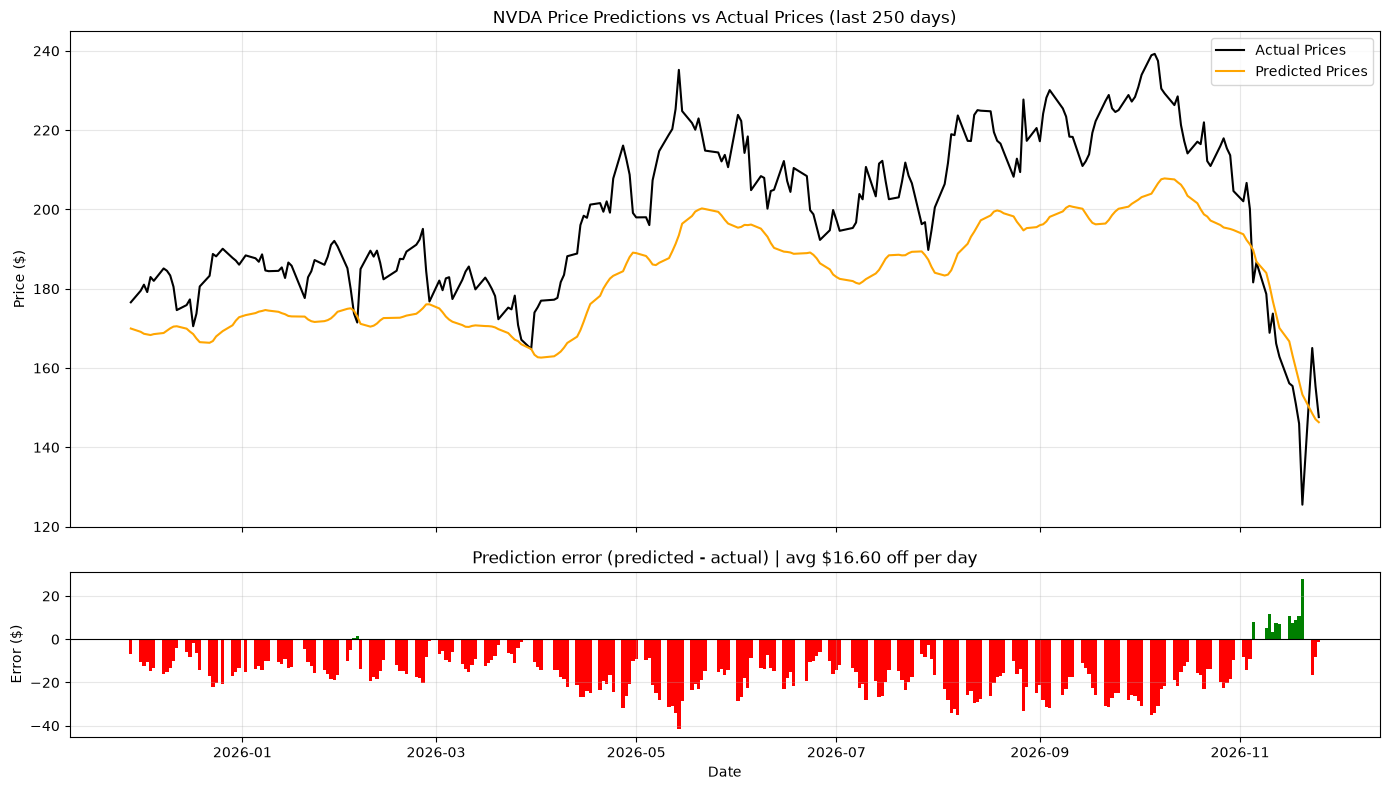

In [5]:
import matplotlib.pyplot as plt

n = 250
dates = df.index[split:][-n:]
a = actual[-n:]
p = pred[-n:]
err = p - a

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(dates, a, label="Actual Prices", color="black")
ax1.plot(dates, p, label="Predicted Prices", color="orange")
ax1.set_title(f"{ticker} Price Predictions vs Actual Prices (last {n} days)")
ax1.set_ylabel("Price ($)")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.bar(dates, err, color=["green" if e >= 0 else "red" for e in err], width=1)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_title(f"Prediction error (predicted - actual) | avg ${abs(err).mean():.2f} off per day")
ax2.set_ylabel("Error ($)")
ax2.set_xlabel("Date")
ax2.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(ROOT / "results" / "lstm_error.png", dpi=140)
plt.show()


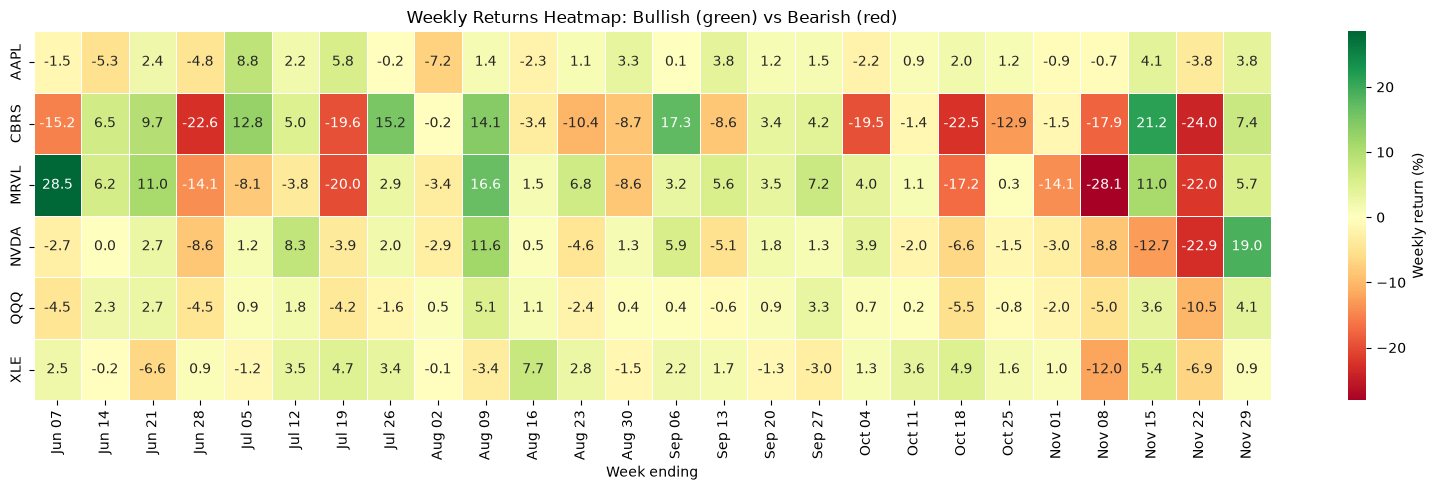

In [6]:
import yfinance as yf
import seaborn as sns
import matplotlib.pyplot as plt

tickers = ["NVDA", "MRVL", "CBRS", "XLE", "QQQ", "AAPL"]
close = yf.download(tickers, period="6mo", progress=False)["Close"]
weekly = close.resample("W").last().pct_change().dropna(how="all") * 100
weekly.index = weekly.index.strftime("%b %d")

plt.figure(figsize=(16, 5))
sns.heatmap(weekly.T, cmap="RdYlGn", center=0, annot=True, fmt=".1f",
            cbar_kws={"label": "Weekly return (%)"}, linewidths=0.5)
plt.title("Weekly Returns Heatmap: Bullish (green) vs Bearish (red)")
plt.xlabel("Week ending")
plt.ylabel("")
plt.tight_layout()
fig = plt.gcf()
fig.savefig(ROOT / "results" / "heatmap.png", dpi=140)
plt.show()


         Bull   Base    Bear
NVDA    750.0  150.0 -1000.0
MRVL    600.0   60.0  -750.0
XLE     100.0   20.0  -100.0
TOTAL  1450.0  230.0 -1850.0


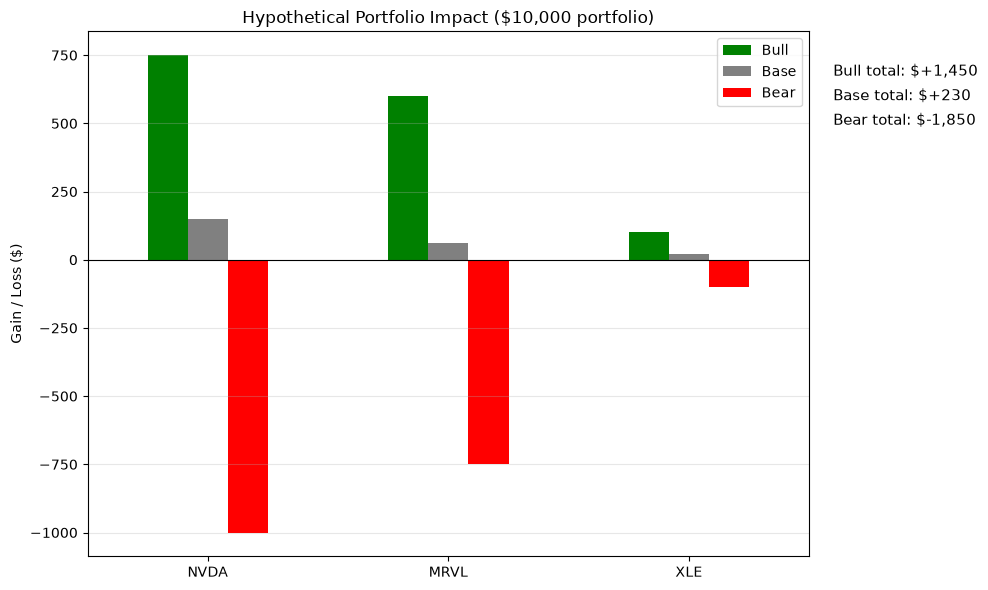

In [7]:
import numpy as np

portfolio_value = 10_000
assets = ["NVDA", "MRVL", "XLE"]
weights = [0.5, 0.3, 0.2]          # must add up to 1

# Hypothetical % moves for each asset under 3 scenarios
scenarios = {
    "Bull": [0.15, 0.20, 0.05],
    "Base": [0.03, 0.02, 0.01],
    "Bear": [-0.20, -0.25, -0.05],
}

dollars = np.array(weights) * portfolio_value
results = {name: dollars * np.array(moves) for name, moves in scenarios.items()}
df = pd.DataFrame(results, index=assets)
df.loc["TOTAL"] = df.sum()
print(df.round(0))

# Plot P&L per asset per scenario
ax = df.drop("TOTAL").plot(kind="bar", figsize=(10, 6), color=["green", "gray", "red"])
for i, (name, total) in enumerate(df.loc["TOTAL"].items()):
    ax.text(2.6, max(df.drop("TOTAL").max()) * (0.9 - i * 0.12),
            f"{name} total: ${total:+,.0f}", fontsize=11)
plt.axhline(0, color="black", linewidth=0.8)
plt.title(f"Hypothetical Portfolio Impact (${portfolio_value:,} portfolio)")
plt.ylabel("Gain / Loss ($)")
plt.xticks(rotation=0)
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [1]:
import yfinance as yf
import pandas as pd
import numpy as np

z_cut = 2.0        # "big move" = more than 2x the asset's normal daily volatility
vol_window = 20    # normal volatility = std of the last 20 daily returns

def signals(close):
    r = close.pct_change()
    vol = r.rolling(vol_window).std().shift(1)   # use yesterday's vol only (no peeking)
    z = r / vol
    nr = r.shift(-1)                              # next day's return
    return r, z, nr

print(f"Daily: up move > {z_cut}x normal volatility\n")
data = {}
for t in ["NVDA", "AMD", "TSLA", "AAPL", "QQQ", "NQ=F"]:
    close = yf.download(t, start="2018-01-01", multi_level_index=False, progress=False)["Close"].dropna()
    r, z, nr = signals(close)
    up = z > z_cut
    data[t] = (nr, up)
    print(f"{t:5} {up.sum():4} days | next day down {(nr[up] < 0).mean():.1%} "
          f"| avg next day {nr[up].mean():+.2%} | normal down rate {(nr < 0).mean():.1%}")

# By-year breakdown for the Nasdaq instruments
for t in ["QQQ", "NQ=F"]:
    nr, up = data[t]
    s = nr[up].dropna()
    table = s.groupby(s.index.year).agg(
        days="count",
        down_rate=lambda x: (x < 0).mean(),
        avg_next="mean",
    )
    table["down_rate"] = (table["down_rate"] * 100).round(1).astype(str) + "%"
    table["avg_next"] = (table["avg_next"] * 100).round(2).astype(str) + "%"
    print(f"\n{t} by year:")
    print(table.to_string())


Daily: up move > 2.0x normal volatility

NVDA    86 days | next day down 50.0% | avg next day -0.03% | normal down rate 46.4%
AMD     89 days | next day down 47.2% | avg next day -0.03% | normal down rate 48.3%
TSLA    92 days | next day down 55.4% | avg next day +0.02% | normal down rate 48.3%
AAPL    90 days | next day down 53.3% | avg next day -0.15% | normal down rate 46.4%
QQQ     65 days | next day down 47.7% | avg next day -0.35% | normal down rate 44.1%
NQ=F    70 days | next day down 42.9% | avg next day -0.11% | normal down rate 44.4%

QQQ by year:
      days down_rate avg_next
Date                         
2018     6     50.0%   -0.74%
2019     7     57.1%    -0.3%
2020     7     71.4%   -2.07%
2021     8     50.0%   -0.14%
2022     6     16.7%    0.39%
2023     7     28.6%    0.25%
2024     8     62.5%   -0.39%
2025     5     80.0%   -0.84%
2026    11     27.3%    0.24%

NQ=F by year:
      days down_rate avg_next
Date                         
2018     7     71.4%   -0.61%


## What this notebook is for

The price-model chart above is the LSTM missing the level of the price and then sitting near it. That is the same lag as the linear regression. The heatmap and the three-scenario portfolio are descriptive. They are not evidence for a strategy.

The daily reversal screen is the bridge to the next notebooks. A fixed +3% day on QQQ showed a high rate of next-day declines in this sample. The volatility-adjusted screen, broken out by year, does not. Notebook 05b moves the same question to NQ hourly bars.
